In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

# The four binary input combinations, used by every section below
X = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])

def step(z):
    """Step activation used throughout the workshop: a = 1 if z > 0, else 0."""
    return (np.asarray(z) > 0).astype(int)

def perceptron(X, w, b):
    """Return (z, a) for every row of X."""
    z = X @ np.asarray(w, dtype=float) + b
    return z, step(z)

def truth_table(name, w, b, X=X):
    z, a = perceptron(X, w, b)
    print(f"{name}:  w = {list(w)},  b = {b}")
    print("  x1 x2 |    z   | a")
    print("  ------+--------+---")
    for (x1, x2), zi, ai in zip(X, z, a):
        print(f"   {x1}  {x2} | {zi:6.2f} | {ai}")
    print()
    return a

# Colours: blue = fires (a = 1), orange = does not fire (a = 0).
# The marker shape also differs (filled circle vs. cross), so the plots
# don't rely on colour alone.
FIRE, NOFIRE = "#2a6fdb", "#e8833a"

def plot_boundary(ax, w, b, title, lim=(-0.5, 2.0), show_points=True,
                  show_normal=True, line_kw=None, shade=True, X=X, labels=None):
    """Shade the a=1 / a=0 regions of a 2-input step perceptron and draw z = 0."""
    w1, w2 = w
    g = np.linspace(*lim, 400)
    G1, G2 = np.meshgrid(g, g)
    Z = w1 * G1 + w2 * G2 + b
    if shade:
        ax.contourf(G1, G2, (Z > 0).astype(int), levels=[-0.5, 0.5, 1.5],
                    colors=[NOFIRE, FIRE], alpha=0.15)
    kw = dict(colors="k", linewidths=2)
    if line_kw:
        kw.update(line_kw)
    ax.contour(G1, G2, Z, levels=[0], **kw)
    if show_points:
        _, a = perceptron(X, w, b)
        for (x1, x2), ai in zip(X, a):
            if ai:
                ax.scatter(x1, x2, s=110, c=FIRE, edgecolors="white", linewidths=2, zorder=3)
            else:
                ax.scatter(x1, x2, s=110, c=NOFIRE, marker="X", edgecolors="white", linewidths=1, zorder=3)
            ax.annotate(f"a={ai}", (x1, x2), textcoords="offset points", xytext=(8, 6), fontsize=9)
    if show_normal:
        # The weight vector (w1, w2) is perpendicular to the boundary and points to the a=1 side
        p = -b * np.array([w1, w2]) / (w1**2 + w2**2)   # closest point on the line to the origin
        n = 0.35 * np.array([w1, w2]) / np.hypot(w1, w2)
        ax.annotate("", xy=p + n, xytext=p, arrowprops=dict(arrowstyle="->", color="k", lw=1.5))
        ax.text(*(p + 1.25 * n), "w", fontsize=10, ha="center", va="center")
    ax.axhline(0, color="0.7", lw=0.8); ax.axvline(0, color="0.7", lw=0.8)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title(title)
    return ax

### Plotting the decision boundary

The workshop's linear-classifier diagram uses a single neuron with weights $w_1 = w_2 = -2$, bias $b = 3$ and a step activation:

$$
z = -2x_1 - 2x_2 + 3, \qquad
a = \begin{cases} 1 & z > 0 \\ 0 & z \le 0 \end{cases}
$$

The **decision boundary** is the set of points where $z = 0$:

$$
-2x_1 - 2x_2 + 3 = 0 \;\;\Longrightarrow\;\; x_2 = -x_1 + 1.5
$$

Below we shade both regions (blue = $a = 1$, orange = $a = 0$), plot the four binary inputs, and print the truth table.

Slide neuron  z = -2x1 - 2x2 + 3:  w = [-2, -2],  b = 3
  x1 x2 |    z   | a
  ------+--------+---
   0  0 |   3.00 | 1
   1  0 |   1.00 | 1
   0  1 |   1.00 | 1
   1  1 |  -1.00 | 0

Matches NAND (NOT (x1 AND x2))? True


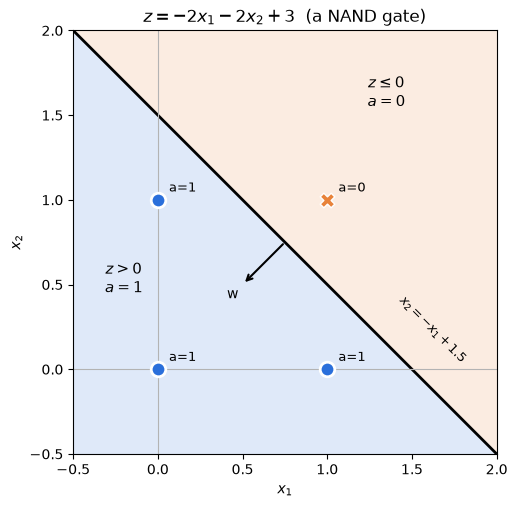

In [2]:
w_nand, b_nand = [-2, -2], 3

a_nand = truth_table("Slide neuron  z = -2x1 - 2x2 + 3", w_nand, b_nand)
nand_expected = 1 - (X[:, 0] & X[:, 1])
print("Matches NAND (NOT (x1 AND x2))?", np.array_equal(a_nand, nand_expected))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_boundary(ax, w_nand, b_nand, "$z = -2x_1 - 2x_2 + 3$  (a NAND gate)")
ax.text(1.35, 1.55, "$z \\leq 0$\n$a = 0$", fontsize=11, ha="center")
ax.text(-0.2, 0.45, "$z > 0$\n$a = 1$", fontsize=11, ha="center")
ax.text(1.62, 0.02, "$x_2 = -x_1 + 1.5$", fontsize=9, rotation=-45, ha="center", va="bottom")
plt.show()

**What the plot shows**

| $x_1$ | $x_2$ | $z$ | $a$ |
|---|---|---|---|
| 0 | 0 | $3$ | 1 |
| 1 | 0 | $1$ | 1 |
| 0 | 1 | $1$ | 1 |
| 1 | 1 | $-1$ | 0 |

The neuron outputs 0 **only** when both inputs are 1. That is the truth table of **NAND** ($\lnot(x_1 \land x_2)$), which the code confirms.

- Three of the points lie on the origin side of the line, where $z > 0$, so they fire. Only $(1,1)$ is on the far side.
- The arrow labelled **w** is the weight vector $(w_1, w_2) = (-2, -2)$. It is always perpendicular to the boundary and points towards the side that fires. Here it points down and to the left, towards the origin.
- NAND is *functionally complete*: any logic circuit can be built from NAND gates alone. We use this in the XOR section below.

### How weights and bias move the line

Solving $w_1x_1 + w_2x_2 + b = 0$ for $x_2$ (assuming $w_2 \neq 0$) gives the line in slope–intercept form:

$$
x_2 = \underbrace{-\frac{w_1}{w_2}}_{\text{slope}}\,x_1 \;\underbrace{-\;\frac{b}{w_2}}_{x_2\text{-intercept}}
$$

The line also crosses the $x_1$-axis at $x_1 = -b/w_1$.

- The **slope depends only on the weights**, so changing a weight **rotates** the line.
- The **bias appears only in the intercepts**, so changing the bias **shifts the line in parallel** without changing its slope.

We test both, starting from the NAND neuron $(w_1, w_2, b) = (-2, -2, 3)$:
1. Change **one weight**: $w_1 = -2 \to -4$, keeping $w_2$ and $b$ fixed.
2. Change **the bias**: $b = 3 \to 1$ and $b = 3 \to 5$, keeping the weights fixed.

experiment        w1  w2   b |  slope  x2-int  x1-int | outputs (00,10,01,11) -> gate
-----------------------------------------------------------------------------------------------
baseline  w1=-2   -2  -2   3 |  -1.00    1.50    1.50 | [1 1 1 0] -> NAND
w1 = -4           -4  -2   3 |  -2.00    1.50    0.75 | [1 0 1 0] -> NOT x1
b = 1             -2  -2   1 |  -1.00    0.50    0.50 | [1 0 0 0] -> NOR
baseline  b=3     -2  -2   3 |  -1.00    1.50    1.50 | [1 1 1 0] -> NAND
b = 5             -2  -2   5 |  -1.00    2.50    2.50 | [1 1 1 1] -> always 1


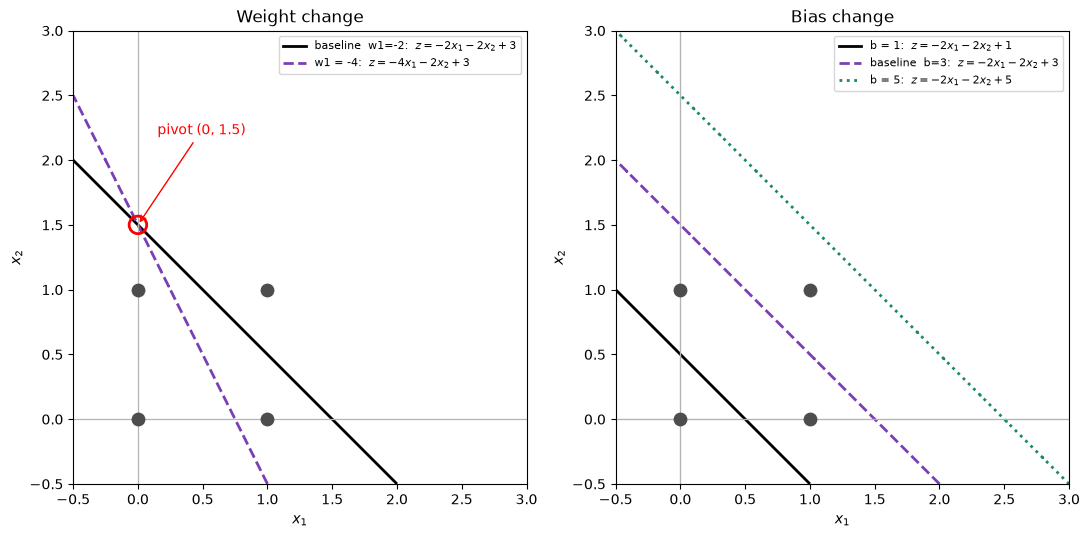

In [3]:
def line_info(w, b):
    w1, w2 = w
    return -w1 / w2, -b / w2, -b / w1      # slope, x2-intercept, x1-intercept

def gate_name(a):
    names = {(1,1,1,0): "NAND", (0,0,0,1): "AND", (0,1,1,1): "OR", (1,0,0,0): "NOR",
             (1,0,1,0): "NOT x1", (1,1,0,0): "NOT x2", (1,1,1,1): "always 1",
             (0,0,0,0): "always 0", (0,1,0,0): "x1 AND NOT x2", (0,1,1,0): "XOR"}
    return names.get(tuple(int(v) for v in a), "other")

experiments = {
    "Weight change": [((-2, -2), 3, "baseline  w1=-2"), ((-4, -2), 3, "w1 = -4")],
    "Bias change":   [((-2, -2), 1, "b = 1"), ((-2, -2), 3, "baseline  b=3"), ((-2, -2), 5, "b = 5")],
}

print(f"{'experiment':<16}{'w1':>4}{'w2':>4}{'b':>4} | {'slope':>6} {'x2-int':>7} {'x1-int':>7} | outputs (00,10,01,11) -> gate")
print("-" * 95)
for group, runs in experiments.items():
    for w, b, label in runs:
        s, i2, i1 = line_info(w, b)
        _, a = perceptron(X, w, b)
        print(f"{label:<16}{w[0]:>4}{w[1]:>4}{b:>4} | {s:>6.2f} {i2:>7.2f} {i1:>7.2f} | {a} -> {gate_name(a)}")

styles = ["-", "--", ":"]
colours = ["k", "#7b3fb5", "#1b8a5a"]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (group, runs) in zip(axes, experiments.items()):
    for k, (w, b, label) in enumerate(runs):
        plot_boundary(ax, w, b, group, lim=(-0.5, 3.0), shade=False, show_normal=False,
                      show_points=False, line_kw=dict(colors=colours[k], linestyles=styles[k]))
        ax.plot([], [], color=colours[k], ls=styles[k], lw=2, label=f"{label}:  $z = {w[0]}x_1 {w[1]:+d}x_2 {b:+d}$")
    ax.scatter(X[:, 0], X[:, 1], s=80, c="0.3", zorder=3)
    ax.legend(loc="upper right", fontsize=8)
axes[0].scatter([0], [1.5], s=160, facecolors="none", edgecolors="r", lw=2, zorder=4)
axes[0].annotate("pivot (0, 1.5)", (0, 1.5), xytext=(0.15, 2.2), arrowprops=dict(arrowstyle="->", color="r"), color="r")
plt.tight_layout()
plt.show()

**Explanation (these numbers match the table printed above)**

**Changing one weight rotates the line.** With $w_1: -2 \to -4$:

$$
\text{slope} = -\frac{w_1}{w_2} = -\frac{-4}{-2} = -2 \quad(\text{was } -1), \qquad
x_2\text{-intercept} = -\frac{b}{w_2} = -\frac{3}{-2} = 1.5 \quad(\text{unchanged})
$$

The $x_2$-intercept does not depend on $w_1$, so the line **pivots about $(0, 1.5)$** and becomes steeper. Its $x_1$-intercept moves from $1.5$ to $-b/w_1 = 0.75$. A larger $|w_1|$ means $x_1$ has more influence on $z$, so the boundary tilts until it lies more across the $x_1$ direction. The point $(1,0)$ now gives $z = -4 + 3 = -1$, so it crosses to the non-firing side. The neuron's behaviour changes from **NAND** to **NOT $x_1$**.

**Changing the bias shifts the line in parallel.** The slope stays at $-1$ for every $b$, but the intercept $-b/w_2 = b/2$ changes:

| $b$ | line | gate |
|---|---|---|
| 1 | $x_2 = -x_1 + 0.5$ | **NOR**: only $(0,0)$ fires |
| 3 | $x_2 = -x_1 + 1.5$ | **NAND** (baseline) |
| 5 | $x_2 = -x_1 + 2.5$ | **always 1**: all four points fire |

The bias sets the neuron's **threshold**. Here $w_2 < 0$, so raising $b$ moves the line *away* from the origin and enlarges the firing region; lowering it does the opposite. With the **same weights**, the bias alone is enough to switch the neuron between three different logic functions.

> Side note: multiplying $w_1$, $w_2$ **and** $b$ by the same positive constant leaves the line (and every step-activation output) unchanged. Multiplying them all by $-1$ keeps the line but swaps which side fires. The next section shows this with AND and NAND.

### Decision boundaries of the workshop's logic gates

Now we use the same plotting function on the three gates from the workshop notebook, with the weights and biases exactly as given there:

| Gate | $w_1$ (A) | $w_2$ (B) | $b$ | Boundary $x_2 = -\frac{w_1}{w_2}x_1 - \frac{b}{w_2}$ |
|---|---|---|---|---|
| AND | 1 | 1 | −1.5 | $x_2 = -x_1 + 1.5$ |
| OR | 1 | 2 | −0.5 | $x_2 = -0.5\,x_1 + 0.25$ |
| A ∧ ¬B | 1 | −1 | −0.5 | $x_2 = x_1 - 0.5$ |

AND:  w = [1, 1],  b = -1.5
  x1 x2 |    z   | a
  ------+--------+---
   0  0 |  -1.50 | 0
   1  0 |  -0.50 | 0
   0  1 |  -0.50 | 0
   1  1 |   0.50 | 1

OR:  w = [1, 2],  b = -0.5
  x1 x2 |    z   | a
  ------+--------+---
   0  0 |  -0.50 | 0
   1  0 |   0.50 | 1
   0  1 |   1.50 | 1
   1  1 |   2.50 | 1

A AND NOT B:  w = [1, -1],  b = -0.5
  x1 x2 |    z   | a
  ------+--------+---
   0  0 |  -0.50 | 0
   1  0 |   0.50 | 1
   0  1 |  -1.50 | 0
   1  1 |  -0.50 | 0

All three gates reproduce their truth tables.


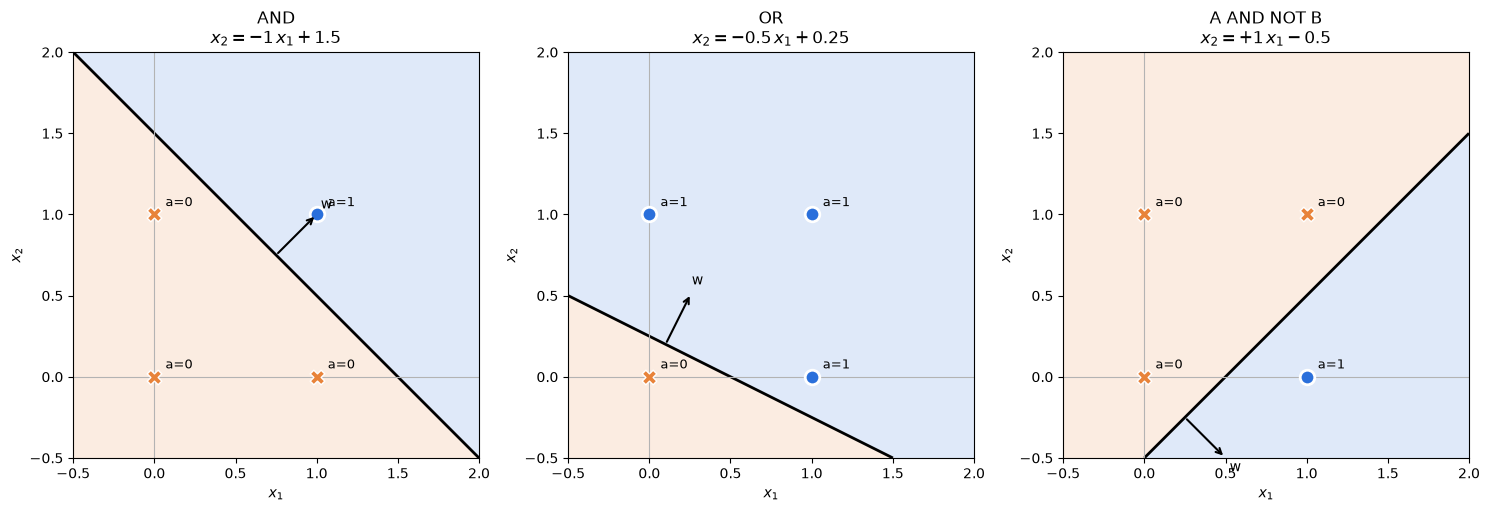

In [4]:
gates = {
    "AND":     ([1, 1],  -1.5, X[:, 0] & X[:, 1]),
    "OR":      ([1, 2],  -0.5, X[:, 0] | X[:, 1]),
    "A AND NOT B": ([1, -1], -0.5, X[:, 0] & (1 - X[:, 1])),
}

for name, (w, b, expected) in gates.items():
    a = truth_table(name, w, b)
    assert np.array_equal(a, expected), f"{name} does not match its truth table!"
print("All three gates reproduce their truth tables.")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, (w, b, _)) in zip(axes, gates.items()):
    s, i2, _ = line_info(w, b)
    plot_boundary(ax, w, b, f"{name}\n$x_2 = {s:+.2g}\\,x_1 {i2:+.2g}$")
plt.tight_layout()
plt.show()

**Observations**

- **AND vs. NAND.** AND $(1, 1, -1.5)$ is exactly $-\tfrac12 \times$ NAND $(-2, -2, 3)$. Both gates therefore have **the same line**, $x_2 = -x_1 + 1.5$, but the weight vector points the opposite way. AND fires *above* the line (only $(1,1)$) and NAND fires *below* it.
- **OR.** The bias $-0.5$ puts the line very close to the origin, so a single active input is enough to cross it. Because $w_2 = 2 > w_1 = 1$, the slope is only $-0.5$: the line is flatter, which shows that B has more influence than A.
- **A ∧ ¬B.** The negative weight on B gives the line a **positive** slope $(+1)$. The firing region is the lower-right triangle, *below* the line. Increasing $x_2$ moves you away from firing, which is the geometric meaning of **inhibition**. Only $(1,0)$ is inside that region.
- In every plot, the arrow **w** points into the blue (firing) region. Which side counts as "above" changes from gate to gate; the direction of **w** is what decides which side fires.

### Why a single perceptron cannot learn XOR

XOR outputs 1 when exactly one input is 1:

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 1 | 0 | 1 |
| 0 | 1 | 1 |
| 1 | 1 | 0 |

The two classes sit on **opposite diagonals** of the square. Any straight line that puts $(1,0)$ and $(0,1)$ on one side also puts at least one of $(0,0)$ or $(1,1)$ on that side. We show this in three ways: a proof, a training experiment and a brute-force search.

**1. Algebraic proof.** A single perceptron would need $(w_1, w_2, b)$ such that

$$
\begin{aligned}
(0,0)\to 0:&\quad b \le 0 \\
(1,0)\to 1:&\quad w_1 + b > 0 \\
(0,1)\to 1:&\quad w_2 + b > 0 \\
(1,1)\to 0:&\quad w_1 + w_2 + b \le 0
\end{aligned}
$$

Adding the two middle inequalities gives $w_1 + w_2 + 2b > 0$, i.e. $w_1 + w_2 + b > -b$. From the first line $-b \ge 0$, so $w_1 + w_2 + b > 0$. This contradicts the last line. **No weights and bias exist**: XOR is not linearly separable.

AND: first epoch with 0 errors = 9, final w = [0.16 0.23], b = -0.30
XOR: min errors in any epoch = 2, errors in last 10 epochs = [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]

Grid search over 1,030,301 (w1, w2, b) combinations in [-5, 5]:
  AND   solutions found:  21,563
  OR    solutions found:  44,775
  NAND  solutions found:  21,421
  XOR   solutions found:       0


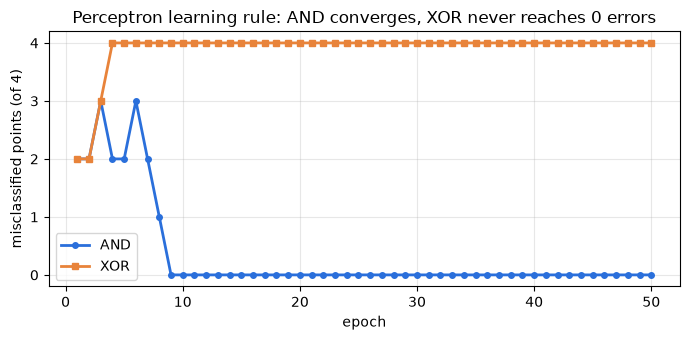

In [5]:
# 2. Training experiment: Rosenblatt's perceptron learning rule
#    w <- w + eta * (y - a) * x,   b <- b + eta * (y - a)
def train_perceptron(X, y, epochs=50, eta=0.1, seed=0):
    rng = np.random.default_rng(seed)
    w, b = rng.normal(0, 0.5, 2), 0.0
    errors = []
    for _ in range(epochs):
        n_err = 0
        for xi, yi in zip(X, y):
            a = int(xi @ w + b > 0)
            w += eta * (yi - a) * xi
            b += eta * (yi - a)
            n_err += int(a != yi)
        errors.append(n_err)
    return w, b, errors

y_and = X[:, 0] & X[:, 1]
y_xor = X[:, 0] ^ X[:, 1]

w_a, b_a, err_and = train_perceptron(X, y_and)
w_x, b_x, err_xor = train_perceptron(X, y_xor)

first_zero = err_and.index(0) + 1 if 0 in err_and else None
print(f"AND: first epoch with 0 errors = {first_zero}, final w = {np.round(w_a, 2)}, b = {b_a:.2f}")
print(f"XOR: min errors in any epoch = {min(err_xor)}, errors in last 10 epochs = {err_xor[-10:]}")

# 3. Brute-force search over a grid of weights and biases
vals = np.linspace(-5, 5, 101)                     # step 0.1 -> 101^3 = 1,030,301 neurons
W1, W2, B = np.meshgrid(vals, vals, vals, indexing="ij")
params = np.stack([W1.ravel(), W2.ravel(), B.ravel()], axis=1)
outs = (params[:, :2] @ X.T + params[:, 2:3] > 0).astype(int)  # shape (n_params, 4)
print(f"\nGrid search over {len(params):,} (w1, w2, b) combinations in [-5, 5]:")
for name, target in [("AND", y_and), ("OR", X[:, 0] | X[:, 1]), ("NAND", 1 - y_and), ("XOR", y_xor)]:
    n = int((outs == target).all(axis=1).sum())
    print(f"  {name:<5} solutions found: {n:>7,}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, 51), err_and, marker="o", ms=4, lw=2, color=FIRE, label="AND")
ax.plot(range(1, 51), err_xor, marker="s", ms=4, lw=2, color=NOFIRE, label="XOR")
ax.set_xlabel("epoch"); ax.set_ylabel("misclassified points (of 4)")
ax.set_yticks(range(5)); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Perceptron learning rule: AND converges, XOR never reaches 0 errors")
plt.tight_layout(); plt.show()

**Results**

- **Training:** on AND, the perceptron learning rule reaches 0 errors within a few epochs. The *perceptron convergence theorem* guarantees this for any linearly separable data. On XOR the error count **never drops to 0**: the line keeps moving back and forth, because fixing one point always misclassifies another.
- **Grid search:** more than a million weight/bias combinations produce thousands of valid AND, OR and NAND neurons, but **zero** XOR neurons. This agrees with the proof.

So the limitation is not about training or about choosing better numbers. A single perceptron can only draw **one straight line**, and XOR needs a region that no single line can produce.

There are two standard solutions, shown below:
1. **Change the input:** add a non-linear feature $x_3 = x_1 x_2$.
2. **Change the network:** add a hidden layer, so two lines are combined.

Solution 1: z = x1 + x2 - 2*x1*x2 - 0.5
  x1=0 x2=0 x1x2=0 -> z=-0.5 -> a=0
  x1=1 x2=0 x1x2=0 -> z=+0.5 -> a=1
  x1=0 x2=1 x1x2=0 -> z=+0.5 -> a=1
  x1=1 x2=1 x1x2=1 -> z=-0.5 -> a=0

Solution 2: XOR = AND( OR(x1,x2), NAND(x1,x2) )
  x1 x2 | h1=OR h2=NAND | z_out | y
   0  0 |   0     1     | -0.5  | 0
   1  0 |   1     1     | +0.5  | 1
   0  1 |   1     1     | +0.5  | 1
   1  1 |   1     0     | -0.5  | 0

Both solutions reproduce XOR exactly.


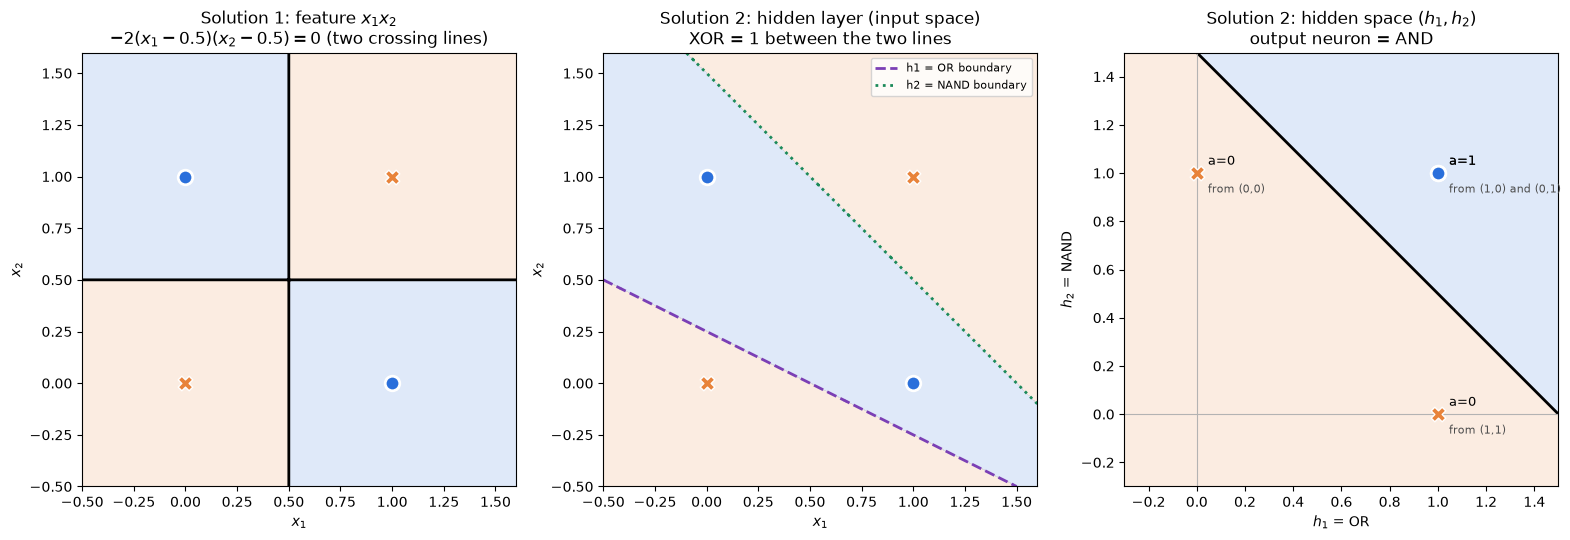

In [6]:
# --- Solution 1: add the feature x1*x2 (still ONE perceptron, now with 3 inputs) ---
w_feat, b_feat = np.array([1, 1, -2]), -0.5
X3 = np.column_stack([X, X[:, 0] * X[:, 1]])
z3, a3 = perceptron(X3, w_feat, b_feat)
print("Solution 1: z = x1 + x2 - 2*x1*x2 - 0.5")
for (x1, x2, x12), zi, ai in zip(X3, z3, a3):
    print(f"  x1={x1} x2={x2} x1x2={x12} -> z={zi:+.1f} -> a={ai}")
assert np.array_equal(a3, y_xor)

# --- Solution 2: two layers, built from gates we already have ---
#   h1 = OR(x1, x2)      workshop OR neuron   (w=[1, 2],  b=-0.5)
#   h2 = NAND(x1, x2)    slide neuron         (w=[-2,-2], b=3)
#   y  = AND(h1, h2)     workshop AND neuron  (w=[1, 1],  b=-1.5)
_, h1 = perceptron(X, [1, 2], -0.5)
_, h2 = perceptron(X, [-2, -2], 3)
H = np.column_stack([h1, h2])
z_out, y_out = perceptron(H, [1, 1], -1.5)
print("\nSolution 2: XOR = AND( OR(x1,x2), NAND(x1,x2) )")
print("  x1 x2 | h1=OR h2=NAND | z_out | y")
for (x1, x2), hh1, hh2, zo, yo in zip(X, h1, h2, z_out, y_out):
    print(f"   {x1}  {x2} |   {hh1}     {hh2}     | {zo:+.1f}  | {yo}")
assert np.array_equal(y_out, y_xor)
print("\nBoth solutions reproduce XOR exactly.")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
lim = (-0.5, 1.6)
g = np.linspace(*lim, 400); G1, G2 = np.meshgrid(g, g)

# (a) feature solution: in the original (x1, x2) space the boundary is two crossing lines
Zf = G1 + G2 - 2 * G1 * G2 - 0.5
axes[0].contourf(G1, G2, (Zf > 0).astype(int), levels=[-0.5, 0.5, 1.5], colors=[NOFIRE, FIRE], alpha=0.15)
axes[0].contour(G1, G2, Zf, levels=[0], colors="k", linewidths=2)
axes[0].set_title("Solution 1: feature $x_1x_2$\n$-2(x_1 - 0.5)(x_2 - 0.5) = 0$ (two crossing lines)")

# (b) two-layer solution: two hidden lines, XOR = the band between them
Z1 = 1 * G1 + 2 * G2 - 0.5
Z2 = -2 * G1 - 2 * G2 + 3
band = ((Z1 > 0) & (Z2 > 0)).astype(int)
axes[1].contourf(G1, G2, band, levels=[-0.5, 0.5, 1.5], colors=[NOFIRE, FIRE], alpha=0.15)
axes[1].contour(G1, G2, Z1, levels=[0], colors="#7b3fb5", linewidths=2, linestyles="--")
axes[1].contour(G1, G2, Z2, levels=[0], colors="#1b8a5a", linewidths=2, linestyles=":")
axes[1].plot([], [], "--", color="#7b3fb5", lw=2, label="h1 = OR boundary")
axes[1].plot([], [], ":", color="#1b8a5a", lw=2, label="h2 = NAND boundary")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].set_title("Solution 2: hidden layer (input space)\nXOR = 1 between the two lines")

for ax in axes[:2]:
    for (x1, x2), yi in zip(X, y_xor):
        if yi: ax.scatter(x1, x2, s=110, c=FIRE, edgecolors="white", lw=2, zorder=3)
        else:  ax.scatter(x1, x2, s=110, c=NOFIRE, marker="X", edgecolors="white", lw=1, zorder=3)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")

# (c) the hidden layer re-maps the points so that ONE line (AND) now separates them
plot_boundary(axes[2], [1, 1], -1.5, "Solution 2: hidden space $(h_1, h_2)$\noutput neuron = AND",
              lim=(-0.3, 1.5), X=H, show_normal=False)
for txt, (hh1, hh2) in [("from (0,0)", (0, 1)), ("from (1,0) and (0,1)", (1, 1)), ("from (1,1)", (1, 0))]:
    axes[2].annotate(txt, (hh1, hh2), textcoords="offset points", xytext=(8, -14), fontsize=8, color="0.3")
axes[2].set_xlabel("$h_1$ = OR"); axes[2].set_ylabel("$h_2$ = NAND")
plt.tight_layout(); plt.show()

**How the two solutions work**

**Solution 1: the feature $x_1x_2$.** With the extra input $x_3 = x_1x_2$, the single neuron

$$z = x_1 + x_2 - 2x_1x_2 - 0.5$$

solves XOR. The term $-2x_1x_2$ only matters at $(1,1)$, where it cancels the $+2$ from the other two inputs. In 3-D space $(x_1, x_2, x_1x_2)$ the boundary is still a flat **plane**. Projected back onto $(x_1, x_2)$, it is no longer one line. Because $x_1 + x_2 - 2x_1x_2 - 0.5 = -2(x_1 - 0.5)(x_2 - 0.5)$, the boundary is the pair of crossing lines $x_1 = 0.5$ and $x_2 = 0.5$, and opposite quadrants share a class (left plot). The perceptron is still linear; we made the *data* linearly separable by choosing a better representation.

**Solution 2: a hidden layer.** XOR is "at least one input is on (OR) **and** not both are on (NAND)":

$$\text{XOR}(x_1, x_2) = \text{AND}\big(\text{OR}(x_1, x_2),\; \text{NAND}(x_1, x_2)\big)$$

- The middle plot shows the two hidden neurons as two lines in input space. XOR fires in the **band between them**, a region one line cannot create.
- The right plot shows the same four points in *hidden space* $(h_1, h_2)$. Both $(1,0)$ and $(0,1)$ map to $(1,1)$. $(0,0)$ maps to $(0,1)$ and $(1,1)$ maps to $(1,0)$. In this space the AND line separates them. The hidden layer **re-maps the inputs until they become linearly separable**, which is the basic reason deep networks work.

**Link to the class notes.** The *Deep Learning Fundamentals* slides make the same point with the Prostate Cancer example. With no hidden layer, the single sigmoid "S" curve "does not work well for this sample data". Once a hidden layer is added, the network can produce a non-linear curve that fits the data. XOR is the smallest example of that idea.

### Correction: which side of the line fires?

The workshop notebook's explanation of the yellow-line diagram says:

> 🟡 **Above the line** → $z > 0$ → $a = 1$
> ⚫ **Below or on the line** → $z \leq 0$ → $a = 0$

**This is reversed.** The diagram itself shades the region **above** the line and labels it "$z \le 0,\ a = 0$", and the maths agrees with the diagram:

- $(0, 0)$ lies **below** the line $x_2 = -x_1 + 1.5$ and gives $z = 3 > 0$, so it **fires** ($a = 1$).
- $(1, 1)$ lies **above** the line and gives $z = -1 \le 0$, so it does **not** fire ($a = 0$).

**Corrected statement**

- **Below the line** (the origin side) → $z > 0$ → $a = 1$
- **On or above the line** → $z \le 0$ → $a = 0$

**General rule:** for $x_2$ above the line, $z$ has the sign of $w_2$. If $w_2 < 0$ (as here) the region *above* gives $z < 0$; if $w_2 > 0$ (as in AND and OR) the region *above* fires. More simply, **the side that fires is the side the weight vector $\mathbf{w}$ points to.** The cell below checks this numerically.

In [7]:
def side(x, w, b):
    """Is point x above, on or below the boundary line (in the x2 direction)?"""
    w1, w2 = w
    line_x2 = -(w1 / w2) * x[0] - b / w2
    return "above" if x[1] > line_x2 + 1e-12 else ("below" if x[1] < line_x2 - 1e-12 else "on")

test_points = np.array([[0, 0], [1, 0], [0, 1], [1, 1], [0.75, 0.75], [2, 2], [-0.5, -0.5]])

for name, w, b in [("NAND slide neuron (w2 < 0)", [-2, -2], 3), ("AND gate (w2 > 0)", [1, 1], -1.5)]:
    z, a = perceptron(test_points, w, b)
    print(name)
    print("   point        | side of line |    z   | a")
    for p, zi, ai in zip(test_points, z, a):
        print(f"   ({p[0]:5.2f},{p[1]:5.2f}) | {side(p, w, b):>12} | {zi:6.2f} | {ai}")
    fired_sides = {side(p, w, b) for p, ai in zip(test_points, a) if ai == 1}
    print(f"   -> points that fire are all: {fired_sides}\n")

NAND slide neuron (w2 < 0)
   point        | side of line |    z   | a
   ( 0.00, 0.00) |        below |   3.00 | 1
   ( 1.00, 0.00) |        below |   1.00 | 1
   ( 0.00, 1.00) |        below |   1.00 | 1
   ( 1.00, 1.00) |        above |  -1.00 | 0
   ( 0.75, 0.75) |           on |   0.00 | 0
   ( 2.00, 2.00) |        above |  -5.00 | 0
   (-0.50,-0.50) |        below |   5.00 | 1
   -> points that fire are all: {'below'}

AND gate (w2 > 0)
   point        | side of line |    z   | a
   ( 0.00, 0.00) |        below |  -1.50 | 0
   ( 1.00, 0.00) |        below |  -0.50 | 0
   ( 0.00, 1.00) |        below |  -0.50 | 0
   ( 1.00, 1.00) |        above |   0.50 | 1
   ( 0.75, 0.75) |           on |   0.00 | 0
   ( 2.00, 2.00) |        above |   2.50 | 1
   (-0.50,-0.50) |        below |  -2.50 | 0
   -> points that fire are all: {'above'}



For the slide neuron, every firing point is **below** the line, and the point $(0.75, 0.75)$, which lies exactly on the line, gives $z = 0 \Rightarrow a = 0$. This confirms the corrected statement. The AND gate fires on the *opposite* side (above), so "above" or "below" on its own does not tell you which side fires. You need the sign of $w_2$, or the direction of $\mathbf{w}$.

### TensorFlow Playground observations

We used [TensorFlow Playground](https://playground.tensorflow.org) to test the XOR results above with real training. All runs used the **XOR** dataset ("exclusive or", the 4-quadrant pattern), the **tanh** activation, learning rate **0.03**, noise 0 and a 50% train/test split. The three experiments, with their configured links, were:

| # | Setup | Link |
|---|---|---|
| A | Inputs $X_1, X_2$ only, **no hidden layer** | [open](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=xor&learningRate=0.03&regularizationRate=0&noise=0&networkShape=&seed=0.12345&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&problem=classification&discretize=false) |
| B | Inputs $X_1, X_2$, **one hidden layer with 4 neurons** | [open](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=xor&learningRate=0.03&regularizationRate=0&noise=0&networkShape=4&seed=0.12345&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&problem=classification&discretize=false) |
| C | Inputs $X_1, X_2$ **plus the feature $X_1X_2$**, no hidden layer | [open](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=xor&learningRate=0.03&regularizationRate=0&noise=0&networkShape=&seed=0.12345&percTrainData=50&x=true&y=true&xTimesY=true&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&problem=classification&discretize=false) |


**A. No hidden layer: fails.**
The output is a single neuron, so the background splits into two halves along **one straight line**. However long it trains, the line only rotates or drifts, and about half the points stay on the wrong side. Test loss stays at about **0.498** after 1000 epochs. This is the same limitation the proof and the grid search showed above.

**B. One hidden layer (4 neurons): succeeds.**
Each hidden neuron learns its own line, which you can see in the small previews of each neuron. The output neuron combines them into a checkerboard-shaped region that matches the four quadrants. The boundary matched the XOR pattern after about 250 epochs, and test loss kept falling slowly, reaching **0.011** after 10,000 epochs. The loss keeps getting smaller without reaching zero, because the network keeps becoming more confident about points it already classifies correctly.

**C. The $X_1X_2$ feature, no hidden layer: succeeds, and fastest.**
The $X_1X_2$ input has the right sign in every quadrant: positive in the 1st and 3rd, negative in the 2nd and 4th. This is exactly the XOR pattern. Training puts almost all the weight on it (the thick connection) and the test loss drops to about **0.014** within about 50 epochs, about 5 times faster than B. This is Solution 1 above: with the right feature, one neuron is enough.

**Takeaways**
1. A perceptron with no hidden layer draws one linear boundary. That is enough for AND/OR/NAND but not for XOR.
2. There are two ways to solve this: **engineer a better feature** (C), or **let a hidden layer learn the features** (B). Deep learning takes the second route, because for real data we usually don't know which features to engineer.
3. The playground's background colours are the same picture as the shaded plots in this notebook: blue and orange regions separated by the decision boundary.